# HUSTmotor — Acoustic CNN + Shape-Feature Fusion

**Université de technologie de Compiègne (UTC)** · Multimodal motor fault diagnosis workshop  
**Acoustic-only experiment | Phase 4B | Z-score waveform + six engineered shape features**

This notebook evaluates whether six source-selected waveform-shape descriptors complement the existing 1D CNN in **leave-one-speed-out motor fault classification** (six classes, four motor speeds).

### What changes from the original baseline?

| Original acoustic CNN | This experiment |
|---|---|
| 1,024-point z-scored acoustic waveform | **Same** acoustic waveform and CNN blocks |
| CNN flatten (3,520 values) → 6-class linear layer | CNN flatten **plus** six-feature MLP (16 values) → 6-class linear layer |
| 50 epochs / Adam / 10 seeds | **Same** optimizer, schedule, epochs, seeds and splits |

**No Random Forest is placed inside the CNN.** The prior Random Forest and source-speed experiments were used to investigate the engineered features. The fusion network learns its own MLP representation end-to-end with cross-entropy loss.

**Research caveat:** The actual unseen-target results from earlier notebooks were already inspected. This is a further **exploratory** comparison, not a fully blind confirmatory evaluation. We will not tune architecture or feature subsets using target outcomes in this notebook.

## 1. Experimental design and fixed feature choice

We use **exactly six shape-related features**: `crest`, `kurtosis`, `clearance`, `shape`, `skewness`, `impulse`.

This group was selected using source-only speed-held-out validation in `HUSTmotor_Acoustic_Source_Domain_Validation.ipynb`. The same group was selected for Tasks 9–12, so it is now **fixed before fusion training**.

| Task | Train + source validation speeds | Unseen target speed |
|---|---|---|
| 9 | 10, 20, 30 Hz | 5 Hz |
| 10 | 5, 20, 30 Hz | 10 Hz |
| 11 | 5, 10, 30 Hz | 20 Hz |
| 12 | 5, 10, 20 Hz | 30 Hz |

**Per-task partitions:** 14,400 source-training, 3,600 source-validation, and 1,200 unseen-target windows. For each task, the shared loader standardizes the six selected features using statistics from **source training only**, and returns **per-window z-score waveform arrays**. The validation data selects the checkpoint; the target data is evaluated only after selection.

**Primary metric:** average unseen-target classification accuracy across the four tasks (10 seeds each). **Secondary:** macro-F1 and confusion matrices. Source-validation accuracy is used for model selection, **not** as a substitute for target accuracy.

## 2. Colab setup — Drive directories

Results from this experiment are saved separately from the original CNN, RMS, and Random Forest experiments. A GPU is recommended for CNN training.

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')
BASE_DIR = Path('/content/drive/MyDrive')
PROJECT_DIR = BASE_DIR / 'HUSTmotor_Acoustic_Fusion'
DATA_DIR = BASE_DIR / 'HUSTmotor_Preprocessing_Comparison' / 'data'
MODELS_DIR = PROJECT_DIR / 'models'
RESULTS_DIR = PROJECT_DIR / 'results'
FIGURES_DIR = PROJECT_DIR / 'figures'
for p in (DATA_DIR, MODELS_DIR, RESULTS_DIR, FIGURES_DIR):
    p.mkdir(parents=True, exist_ok=True)
print('Fusion experiment folder:', PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Fusion experiment folder: /content/drive/MyDrive/HUSTmotor_Acoustic_Fusion


## 3. Imports, configuration and reproducibility

**Training protocol:** four original convolutional blocks; Adam, 50 epochs, batch size 256, learning rate `0.0005 / (1 + 10p)^0.75`, seed IDs 0–9.

We retain the original baseline model's flattening convention and valid convolutions. The only new design choice is a deliberately small 6 → 16 → 16 feature branch with ReLU and fusion into a six-class linear layer. This **is not architecture-identical** to the baseline, but the training conditions are kept aligned.

A seed controls random initialization and data shuffling. GPU arithmetic can still introduce minor runtime-dependent differences.

In [ ]:
import os, json, hashlib, random, subprocess, platform
from copy import deepcopy
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 256
EPOCHS = 50
BASE_LR = 0.0005
TASKS = (9, 10, 11, 12)
SEEDS = tuple(range(10))
TASK_TO_DOMAIN = {9:0, 10:1, 11:2, 12:3}
DOMAIN_TO_HZ = {0:5, 1:10, 2:20, 3:30}
CLASS_NAMES = ['Healthy', 'Bearing fault', 'Bowed rotor',
               'Broken rotor bars', 'Misalignment', 'Voltage unbalance']
SHAPE_FEATURES = ['crest', 'kurtosis', 'clearance', 'shape', 'skewness', 'impulse']
NORM = 'zscore'

# Safety switches — train a smoke test first, then explicitly enable 40 runs.
RUN_SMOKE_TEST = True
RUN_FULL_EXPERIMENT = True
# When True, safely load existing matching checkpoints rather than retraining them.
REUSE_MATCHING_CHECKPOINTS = True

print('Device:', DEVICE)
print('Full experiment:', len(TASKS) * len(SEEDS), 'trials')

Device: cpu
Full experiment: 40 trials


## 4. Clone the shared preprocessing implementation

Pin the exact source version in our experiment metadata. We use the preprocessing repository by **Gentian Qinami**; the acoustic features are computed upstream from DC-removed waveform windows.

Repository: https://github.com/Genti24-bit/ISCF_Project

In [ ]:
import sys
REPO_URL = 'https://github.com/Genti24-bit/ISCF_Project.git'
REPO_DIR = Path('/content/ISCF_Project')
if not (REPO_DIR / 'preprocess_hustmotor.py').exists():
    subprocess.run(['git', 'clone', '--quiet', REPO_URL, str(REPO_DIR)], check=True)
PREPROCESS_COMMIT = subprocess.check_output(
    ['git','-C',str(REPO_DIR),'rev-parse','HEAD'], text=True
).strip()
sys.path.insert(0,str(REPO_DIR))
from preprocess_hustmotor import load_dg_task
print('Preprocessing commit:', PREPROCESS_COMMIT)

Preprocessing commit: 7e0820c612d402a98abe554c6e6c9ddf490600c6


## 5. Download/reuse HUSTmotor v1.3 and verify integrity

Release: https://github.com/Genti24-bit/ISCF_Project/releases/tag/v1.3  
File: `hustmotor_1024_v1.3.npz`  
Expected SHA-256: `605a041d35aab9a12749d9f5f45580cca87e0b5b63b8330bcafdb215da3a8e7d`

The same 1,024-sample acoustic waveform and 11 time-domain descriptors correspond to each row. We do **not** upload the dataset to GitHub.

In [ ]:
from urllib.request import urlretrieve
DATA_PATH = DATA_DIR / 'hustmotor_1024_v1.3.npz'
DATA_URL = ('https://github.com/Genti24-bit/ISCF_Project/releases/download/v1.3/'
            'hustmotor_1024_v1.3.npz')
EXPECTED_SHA256 = '605a041d35aab9a12749d9f5f45580cca87e0b5b63b8330bcafdb215da3a8e7d'
if not DATA_PATH.exists():
    print('Downloading the verified v1.3 archive...')
    urlretrieve(DATA_URL, DATA_PATH)

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''):
            digest.update(chunk)
    return digest.hexdigest()

assert sha256_file(DATA_PATH) == EXPECTED_SHA256, 'Dataset checksum mismatch!'
with np.load(DATA_PATH) as d:
    assert d['ac'].shape == (24000,1024)
    assert d['feat_a'].shape == (24000,11)
print('Verified:',DATA_PATH)

Verified: /content/drive/MyDrive/HUSTmotor_Preprocessing_Comparison/data/hustmotor_1024_v1.3.npz


## 6. Load Task 9, align waveform and shape features

The loader returns `(vibration, acoustic, labels)` for waveforms but `(vibration_features, acoustic_features)` for engineered features. We use the **acoustic** element in each tuple.

The waveform is per-window **z-scored**. The engineered feature arrays are standardized **column-wise** with source-training mean and standard deviation for this task; this preprocessing does not use the target domain. For this experiment, we use only the selected six dimensionless shape features.

In [ ]:
def load_fusion_task(task_number):
    assert task_number in TASK_TO_DOMAIN
    td = TASK_TO_DOMAIN[task_number]
    t = load_dg_task(str(DATA_PATH),target_domain=td,norm='zscore',features=True)
    feat_names = list(t['feat_names'])
    assert all(f in feat_names for f in SHAPE_FEATURES)
    idx = [feat_names.index(f) for f in SHAPE_FEATURES]
    packed = {}
    for split, expected in [('train',14400),('val',3600),('target',1200)]:
        _vib, ac, y = t[split]
        _fv, fa = t[split+'_feat']
        X = np.asarray(ac,dtype=np.float32)
        F = np.asarray(fa[:,idx],dtype=np.float32)
        Y = np.asarray(y,dtype=np.int64)
        assert X.shape == (expected,1024)
        assert F.shape == (expected,len(SHAPE_FEATURES))
        assert Y.shape == (expected,)
        assert np.isfinite(X).all() and np.isfinite(F).all()
        packed[split] = (X,F,Y)
    return packed

sample_task = load_fusion_task(9)
for split, (X,F,y) in sample_task.items():
    print(split, 'waveform:',X.shape,'features:',F.shape,'labels:',y.shape,
          'counts:',np.bincount(y,minlength=6))
print('Shape features:',SHAPE_FEATURES)

train waveform: (14400, 1024) features: (14400, 6) labels: (14400,) counts: [2400 2400 2400 2400 2400 2400]
val waveform: (3600, 1024) features: (3600, 6) labels: (3600,) counts: [600 600 600 600 600 600]
target waveform: (1200, 1024) features: (1200, 6) labels: (1200,) counts: [200 200 200 200 200 200]
Shape features: ['crest', 'kurtosis', 'clearance', 'shape', 'skewness', 'impulse']


## 7. Build paired PyTorch DataLoaders

Each batch consists of three aligned tensors:

- `waveforms`: `(batch, 1, 1024)` — same input format as the original CNN.
- `shape_features`: `(batch, 6)` — separate feature branch.
- `labels`: integer class IDs 0–5.

Never shuffle waveforms and feature arrays separately.

In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def make_loader(split_tuple, shuffle=False, seed=0):
    X,F,y = split_tuple
    dataset = TensorDataset(
        torch.from_numpy(X).float().unsqueeze(1),
        torch.from_numpy(F).float(),
        torch.from_numpy(y).long()
    )
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(dataset,batch_size=BATCH_SIZE,shuffle=shuffle,
                      generator=generator,num_workers=0,
                      pin_memory=(DEVICE.type=='cuda'))

smoke_loader = make_loader(sample_task['train'],shuffle=True,seed=0)
wave, feats, labels = next(iter(smoke_loader))
print('Batch:',wave.shape,feats.shape,labels.shape)
assert wave.shape[1:] == (1,1024) and feats.shape[1] == 6

Batch: torch.Size([256, 1, 1024]) torch.Size([256, 6]) torch.Size([256])


## 8. Define the dual-branch acoustic CNN

**Waveform branch:** exactly the same four convolutional blocks and `padding=0` as our original acoustic CNN, producing a 3,520-dimensional flattened representation.

**Feature branch:** a small MLP (`6 → 16 → 16`, ReLU activations) for the six source-selected acoustic descriptors.

**Fusion:** concatenate the 3,520 and 16 representations → one linear six-class classifier.

This design keeps the convolutional extractor unchanged, but is an **architectural ablation** rather than a drop-in preprocessing change. It adds a small amount of model capacity; any gain cannot automatically be attributed to feature information alone. A feature-shuffling or zero-feature control would be a useful follow-up.

In [ ]:
class AcousticShapeFusionCNN(nn.Module):
    def __init__(self,n_features=6,n_classes=6):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1,16,64,stride=1,padding=0),
            nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2,2),
            nn.Conv1d(16,32,16,stride=1,padding=0),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2,2),
            nn.Conv1d(32,64,5,stride=1,padding=0),
            nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2,2),
            nn.Conv1d(64,64,5,stride=1,padding=0),
            nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2,2)
        )
        # Match the original baseline feature dimensionality exactly.
        was_training = self.features.training
        self.features.eval()
        with torch.no_grad():
            n_flat = self.features(torch.zeros(2,1,1024)).flatten(1).shape[1]
        self.features.train(was_training)
        assert n_flat == 3520
        self.shape_branch = nn.Sequential(
            nn.Linear(n_features,16),nn.ReLU(),
            nn.Linear(16,16),nn.ReLU()
        )
        self.classifier = nn.Linear(n_flat+16,n_classes)

    def forward(self,x_wave,x_shape):
        h_wave = self.features(x_wave).flatten(1)
        h_shape = self.shape_branch(x_shape)
        return self.classifier(torch.cat([h_wave,h_shape],dim=1))

fusion_model = AcousticShapeFusionCNN().to(DEVICE)
with torch.no_grad():
    logits = fusion_model(wave[:4].to(DEVICE),feats[:4].to(DEVICE))
assert logits.shape==(4,6)
print('Output logits:',logits.shape)
print('Trainable parameters:',sum(p.numel() for p in fusion_model.parameters()))

Output logits: torch.Size([4, 6])
Trainable parameters: 62070


## 9. Training and evaluation utilities

Exactly as in the baseline, training minimizes **cross-entropy**, the learning rate follows `0.0005/(1+10p)^0.75`, and the **best epoch is chosen only from source-validation accuracy**. A tie keeps the earlier epoch.

The evaluation function returns predictions so that we can calculate macro-F1 and confusion matrices later. It is used on the actual target set **only after a trained model's best source-validation checkpoint has been selected**.

In [ ]:
def paper_lr(epoch, total_epochs):
    p = epoch / total_epochs
    return BASE_LR/((1+10*p)**0.75)

@torch.no_grad()
def evaluate(model,loader,criterion=None):
    model.eval()
    loss_sum=0.0; num=0; true=[]; pred=[]
    for x,f,y in loader:
        x=x.to(DEVICE,non_blocking=True)
        f=f.to(DEVICE,non_blocking=True)
        y=y.to(DEVICE,non_blocking=True)
        logits=model(x,f)
        if criterion is not None:
            loss_sum+=criterion(logits,y).item()*y.numel()
        num+=y.numel()
        true.append(y.cpu().numpy())
        pred.append(logits.argmax(1).cpu().numpy())
    yt=np.concatenate(true); yp=np.concatenate(pred)
    return {'loss':loss_sum/num if criterion else np.nan,
            'accuracy':accuracy_score(yt,yp),
            'macro_f1':f1_score(yt,yp,labels=np.arange(6),average='macro',zero_division=0),
            'y_true':yt,'y_pred':yp}

def train_model(train_part,val_part,seed=0,epochs=EPOCHS,verbose=False):
    set_seed(seed)
    tr_loader=make_loader(train_part,shuffle=True,seed=seed)
    va_loader=make_loader(val_part,shuffle=False)
    model=AcousticShapeFusionCNN().to(DEVICE)
    criterion=nn.CrossEntropyLoss()
    opt=torch.optim.Adam(model.parameters(),lr=BASE_LR)
    best_acc=-1.0; best_epoch=-1; best_state=None; history=[]
    for epoch in range(epochs):
        lr=paper_lr(epoch,epochs)
        for group in opt.param_groups:
            group['lr']=lr
        model.train(); n=0; train_correct=0; train_loss=0.0
        for x,f,y in tr_loader:
            x=x.to(DEVICE,non_blocking=True)
            f=f.to(DEVICE,non_blocking=True)
            y=y.to(DEVICE,non_blocking=True)
            opt.zero_grad(set_to_none=True)
            logits=model(x,f)
            loss=criterion(logits,y)
            loss.backward()
            opt.step()
            n+=y.numel()
            train_correct+=(logits.argmax(1)==y).sum().item()
            train_loss+=loss.item()*y.numel()
        val=evaluate(model,va_loader,criterion)
        history.append({'epoch':epoch+1,'lr':lr,'train_loss':train_loss/n,
                        'train_acc':train_correct/n,'val_loss':val['loss'],
                        'val_acc':val['accuracy'],'val_macro_f1':val['macro_f1']})
        if val['accuracy']>best_acc:
            best_acc=val['accuracy'];best_epoch=epoch+1
            best_state=deepcopy(model.state_dict())
        if verbose and (epoch==0 or (epoch+1)%5==0 or epoch==epochs-1):
            print(f'Epoch {epoch+1}/{epochs} | train {100*train_correct/n:.2f}% '
                  f'| val {100*val["accuracy"]:.2f}% | lr {lr:.6f}')
    model.load_state_dict(best_state)
    return model,pd.DataFrame(history),best_epoch,best_acc

## 10. Optional two-epoch smoke test (source data only)

A quick check that loss decreases and the model runs end-to-end. A **two-epoch result is not scientifically comparable** with the 50-epoch baseline, and this cell never evaluates the unseen target.

In [ ]:
if RUN_SMOKE_TEST:
    smoke_model,smoke_history,_,_=train_model(
        sample_task['train'],sample_task['val'],seed=0,epochs=2,verbose=True)
    display(smoke_history)
    print('Smoke test passed. The unseen target set was not evaluated.')
else:
    print('Smoke test skipped.')

Epoch 1/2 | train 54.31% | val 64.14% | lr 0.000500
Epoch 2/2 | train 77.08% | val 75.75% | lr 0.000130


,epoch,lr,train_loss,train_acc,val_loss,val_acc,val_macro_f1
0,1,0.00050,1.083657,0.543056,0.823497,0.641389,0.618852
1,2,0.00013,0.553297,0.770764,0.540578,0.757500,0.759586


Smoke test passed. The unseen target set was not evaluated.


## 11. Full experiment — 4 tasks × 10 seeds (40 trainings)

Set `RUN_FULL_EXPERIMENT = True` in **Section 3** when ready. Each task/seed uses **50 epochs**, saves a checkpoint and a history CSV to Drive, and evaluates unseen-target accuracy **only after** source-validation checkpoint selection. Existing checkpoints with matching metadata can be reused.

**Practical advice:** This is a substantial GPU experiment. Colab sessions can disconnect. The loop saves each result immediately; rerunning with `REUSE_MATCHING_CHECKPOINTS = True` can resume without retraining completed task/seed checkpoints.

*Do not change feature choices or model architecture after inspecting target results and describe the same results as a blind evaluation.*

In [ ]:
RUN_CSV=RESULTS_DIR/'fusion_10runs_raw.csv'

def checkpoint_path(task,seed):
    return MODELS_DIR/f'fusion_task{task}_seed{seed}.pt'

def load_checkpoint_if_valid(path,task,seed):
    if not path.exists():
        return None
    ck=torch.load(path,map_location='cpu',weights_only=False)
    expected={'task':task,'seed':seed,'norm':'zscore','dataset_sha256':EXPECTED_SHA256,
              'feature_names':SHAPE_FEATURES,'epochs':EPOCHS,
              'batch_size':BATCH_SIZE,'lr_base':BASE_LR}
    for k,v in expected.items():
        if ck.get(k)!=v:
            raise ValueError(f'Existing checkpoint {path} has mismatched {k}: {ck.get(k)}')
    return ck

def run_one(task,seed):
    part=load_fusion_task(task)
    path=checkpoint_path(task,seed)
    ck=load_checkpoint_if_valid(path,task,seed) if REUSE_MATCHING_CHECKPOINTS else None
    if ck is not None:
        print(f'Reusing checkpoint: task {task}, seed {seed}')
        model=AcousticShapeFusionCNN().to(DEVICE)
        model.load_state_dict(ck['model_state_dict'])
        best_epoch=ck['best_epoch']; best_acc=ck['best_val_acc']
    else:
        model,hist,best_epoch,best_acc=train_model(
            part['train'],part['val'],seed=seed,epochs=EPOCHS,verbose=False)
        ck={'task':task,'seed':seed,'norm':'zscore','dataset_sha256':EXPECTED_SHA256,
            'preprocessing_commit':PREPROCESS_COMMIT,'feature_names':list(SHAPE_FEATURES),
            'epochs':EPOCHS,'batch_size':BATCH_SIZE,'lr_base':BASE_LR,
            'best_epoch':best_epoch,'best_val_acc':float(best_acc),
            'model_state_dict':model.state_dict()}
        torch.save(ck,path)
        hist.to_csv(RESULTS_DIR/f'fusion_history_task{task}_seed{seed}.csv',index=False)
    # The actual unseen target is used for REPORTING ONLY, never for model selection.
    target=evaluate(model,make_loader(part['target'],shuffle=False),nn.CrossEntropyLoss())
    return {'task':task,'target_hz':DOMAIN_TO_HZ[TASK_TO_DOMAIN[task]],
            'seed':seed,'best_epoch':best_epoch,'source_val_acc':100*best_acc,
            'target_acc':100*target['accuracy'],
            'target_macro_f1':target['macro_f1']}

if RUN_FULL_EXPERIMENT:
    all_rows=[]
    for task in TASKS:
        for seed in SEEDS:
            row=run_one(task,seed)
            all_rows.append(row)
            # Save incrementally, so a Colab interruption does not lose completed scores.
            pd.DataFrame(all_rows).to_csv(RUN_CSV,index=False)
            print(f'Task {task} seed {seed}: target accuracy {row["target_acc"]:.2f}%')
    print('Completed:',len(all_rows),'runs. Saved:',RUN_CSV)
else:
    print('Full training disabled. Set RUN_FULL_EXPERIMENT=True in Section 3 when ready.')

Reusing checkpoint: task 9, seed 0
Task 9 seed 0: target accuracy 28.25%
Reusing checkpoint: task 9, seed 1
Task 9 seed 1: target accuracy 23.50%
Reusing checkpoint: task 9, seed 2
Task 9 seed 2: target accuracy 25.08%
Reusing checkpoint: task 9, seed 3
Task 9 seed 3: target accuracy 24.42%
Reusing checkpoint: task 9, seed 4
Task 9 seed 4: target accuracy 28.33%
Reusing checkpoint: task 9, seed 5
Task 9 seed 5: target accuracy 27.17%
Reusing checkpoint: task 9, seed 6
Task 9 seed 6: target accuracy 25.83%
Reusing checkpoint: task 9, seed 7
Task 9 seed 7: target accuracy 26.58%
Reusing checkpoint: task 9, seed 8
Task 9 seed 8: target accuracy 24.92%
Reusing checkpoint: task 9, seed 9
Task 9 seed 9: target accuracy 24.92%
Reusing checkpoint: task 10, seed 0
Task 10 seed 0: target accuracy 65.00%
Reusing checkpoint: task 10, seed 1
Task 10 seed 1: target accuracy 61.58%
Reusing checkpoint: task 10, seed 2
Task 10 seed 2: target accuracy 57.17%
Reusing checkpoint: task 10, seed 3
Task 10 s

## 12. Summarize completed runs and compare with baseline

This cell reads the saved result CSV if available. It does not train anything. It expects **40 completed runs** before producing the final paper-style table.

**CNN z-score benchmark (previous experiment):** 48.45 ± 2.14% overall (seed-wise average), across 10 trials per task. The RMS CNN (38.19%) is included as additional context. These are historical results; the corresponding z-score v1.0 and fusion v1.3 configurations should be verified separately if claiming strict normalization/architecture equivalence.

In [14]:
BASELINE_ZSCORE = {9:(26.36,3.00),10:(60.96,4.02),
                   11:(57.29,4.88),12:(49.19,2.80)}
BASELINE_RMS = {9:24.68,10:44.88,11:41.14,12:42.04}
if RUN_CSV.exists():
    raw_df=pd.read_csv(RUN_CSV)
    print('Saved run rows:',len(raw_df),'/ 40')
    assert not raw_df.duplicated(['task','seed']).any()
    if len(raw_df)==40:
        assert set(raw_df['task'])==set(TASKS)
        for task in TASKS:
            assert set(raw_df.loc[raw_df.task==task,'seed'])==set(SEEDS)
        summary_df=(raw_df.groupby('task',as_index=False)
            .agg(target_mean=('target_acc','mean'),target_sd=('target_acc','std'),
                 macro_f1_mean=('target_macro_f1','mean'),
                 mean_best_epoch=('best_epoch','mean')))
        summary_df['target_hz']=summary_df['task'].map(
            lambda task:DOMAIN_TO_HZ[TASK_TO_DOMAIN[task]])
        summary_df['zscore_cnn_mean']=summary_df['task'].map(lambda x:BASELINE_ZSCORE[x][0])
        summary_df['rms_cnn_mean']=summary_df['task'].map(BASELINE_RMS)
        summary_df['delta_vs_zscore_pp']=summary_df['target_mean']-summary_df['zscore_cnn_mean']
        display(summary_df.round(3))
        summary_df.to_csv(RESULTS_DIR/'fusion_10runs_summary.csv',index=False)
        per_seed_avg=raw_df.groupby('seed')['target_acc'].mean()
        print(f'Fusion overall: {per_seed_avg.mean():.2f} ± {per_seed_avg.std(ddof=1):.2f}%')
        print(f'Original z-score CNN overall: 48.45 ± 2.14%')
        print(f'Fusion minus z-score baseline: {per_seed_avg.mean()-48.45:+.2f} percentage points')
    else:
        print('Partial training only: full summary will be available after all 40 runs.')
else:
    print('No results yet; enable full experiment and run Section 11.')

Saved run rows: 40 / 40


,task,target_mean,target_sd,macro_f1_mean,mean_best_epoch,target_hz,zscore_cnn_mean,rms_cnn_mean,delta_vs_zscore_pp
0,9,25.900,1.636,0.229,42.9,5,26.36,24.68,-0.460
1,10,60.983,3.226,0.581,42.6,10,60.96,44.88,0.023
2,11,59.233,2.713,0.594,41.6,20,57.29,41.14,1.943
3,12,49.758,2.842,0.479,41.4,30,49.19,42.04,0.568


Fusion overall: 48.97 ± 1.71%
Original z-score CNN overall: 48.45 ± 2.14%
Fusion minus z-score baseline: +0.52 percentage points


## 13. Re-evaluate all 40 saved checkpoints and inspect class-wise performance

This independent evaluation reloads the **40 saved model weights**, confirms checkpoint metadata, computes macro-F1 and row-normalized confusion matrices, and checks the accuracy against the saved training-run CSV. It never changes weights or selects models based on the target.

If training is unfinished, the cell prints a message and skips evaluation.

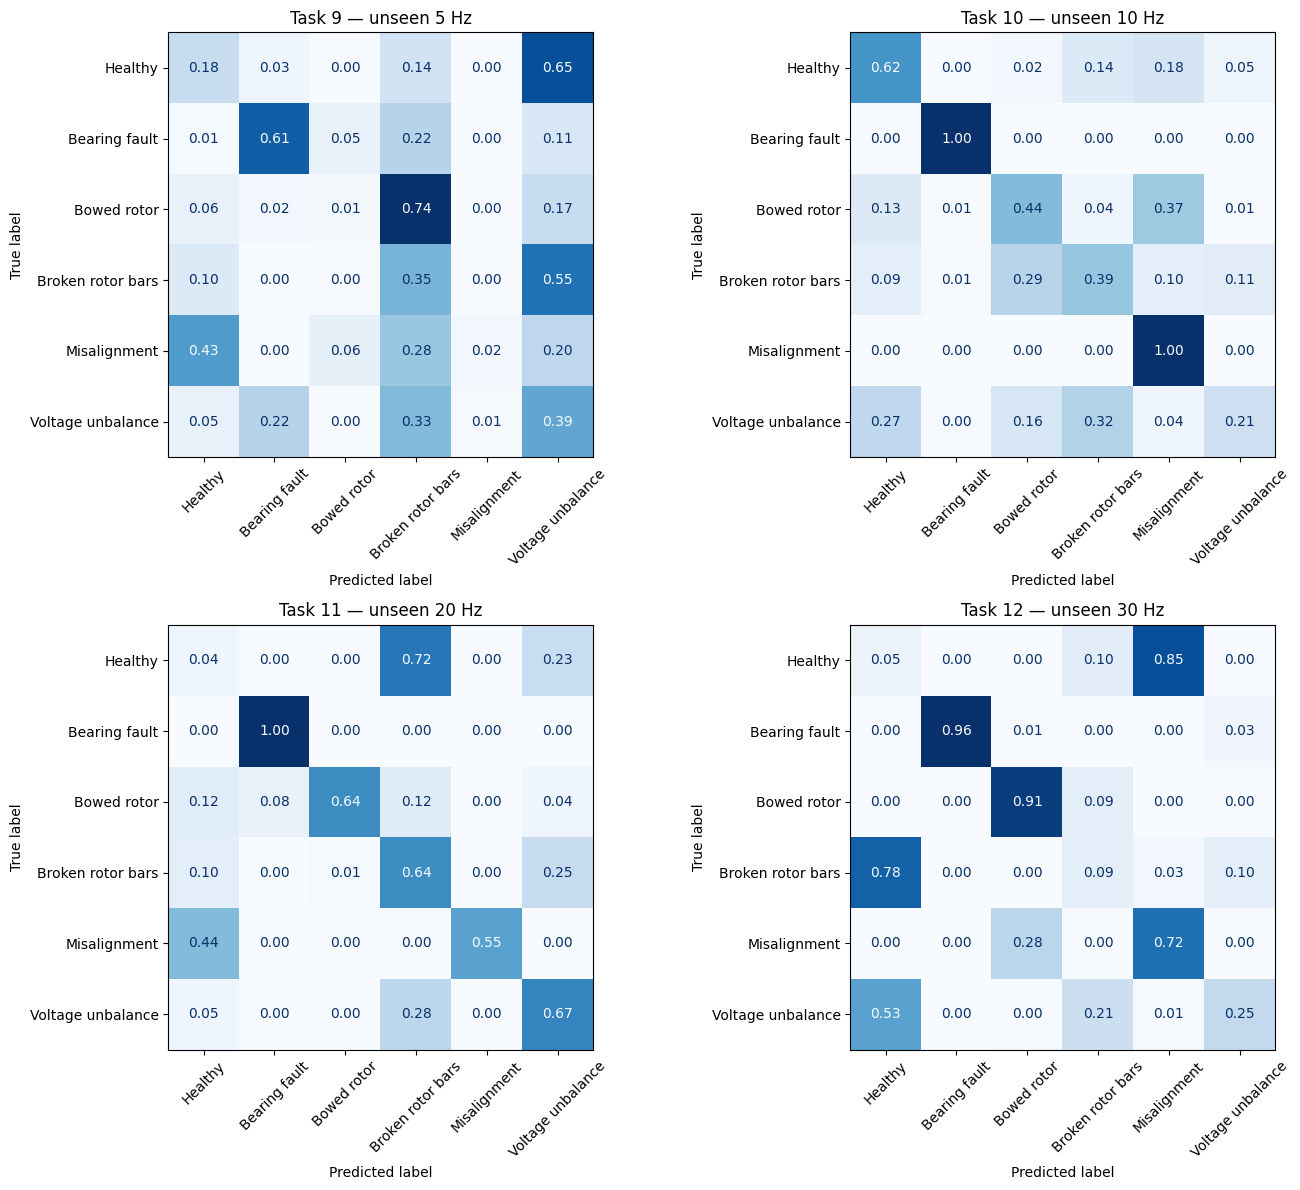

PASS: All 40 saved accuracies reproduced from checkpoints.


In [15]:
if RUN_CSV.exists() and len(pd.read_csv(RUN_CSV))==40:
    rows=[]; matrices={task:[] for task in TASKS}; class_rows=[]
    raw_df=pd.read_csv(RUN_CSV)
    for task in TASKS:
        part=load_fusion_task(task)
        loader=make_loader(part['target'],shuffle=False)
        for seed in SEEDS:
            ck=load_checkpoint_if_valid(checkpoint_path(task,seed),task,seed)
            if ck is None:
                raise FileNotFoundError(checkpoint_path(task,seed))
            model=AcousticShapeFusionCNN().to(DEVICE)
            model.load_state_dict(ck['model_state_dict'])
            met=evaluate(model,loader,nn.CrossEntropyLoss())
            old=raw_df[(raw_df.task==task)&(raw_df.seed==seed)].iloc[0]
            assert abs(100*met['accuracy']-float(old.target_acc))<1e-4
            rows.append({'task':task,'seed':seed,'target_accuracy':100*met['accuracy'],
                         'macro_f1':met['macro_f1']})
            cm=confusion_matrix(met['y_true'],met['y_pred'],labels=np.arange(6),normalize='true')
            matrices[task].append(cm)
            for cls in range(6):
                true_mask=(met['y_true']==cls)
                class_rows.append({'task':task,'seed':seed,'class':CLASS_NAMES[cls],
                                   'recall':float(np.mean(met['y_pred'][true_mask]==cls))})
    pd.DataFrame(rows).to_csv(RESULTS_DIR/'fusion_checkpoint_recheck.csv',index=False)
    pd.DataFrame(class_rows).to_csv(RESULTS_DIR/'fusion_class_recall.csv',index=False)
    fig,axs=plt.subplots(2,2,figsize=(14,12))
    for ax,task in zip(axs.flat,TASKS):
        mean_cm=np.mean(matrices[task],axis=0)
        ConfusionMatrixDisplay(mean_cm,display_labels=CLASS_NAMES).plot(
            ax=ax,cmap='Blues',values_format='.2f',colorbar=False)
        ax.set_title(f'Task {task} — unseen {DOMAIN_TO_HZ[TASK_TO_DOMAIN[task]]} Hz')
        ax.tick_params(axis='x',labelrotation=45)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR/'fusion_mean_target_confusion_matrices.png',dpi=170,bbox_inches='tight')
    plt.show()
    print('PASS: All 40 saved accuracies reproduced from checkpoints.')
else:
    print('Evaluation deferred until 40 full runs are completed.')

## 14. Plot the 10-seed accuracy comparison

The bar chart compares target accuracy by task. The previous CNN z-score and RMS figures are for context. **No new scientific conclusion should be drawn until 40 full fusion runs exist.**

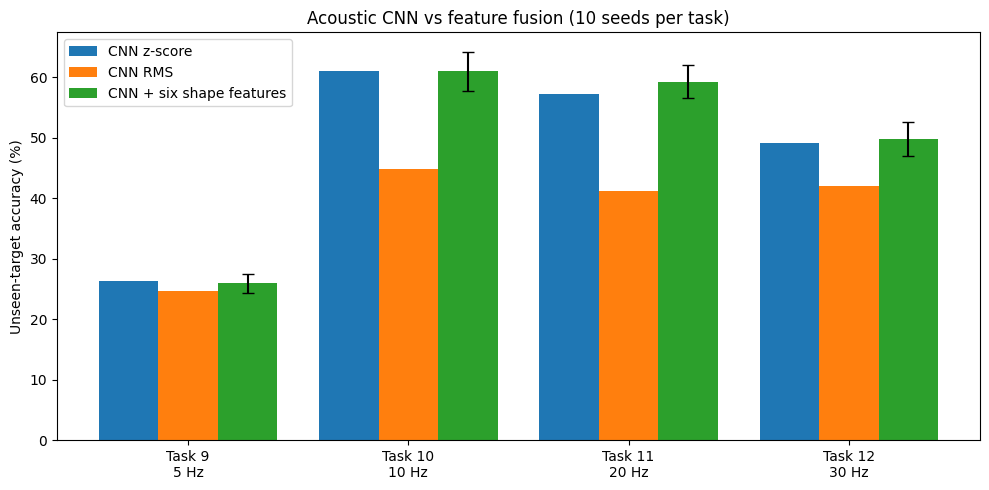

In [16]:
if RUN_CSV.exists() and len(pd.read_csv(RUN_CSV))==40:
    fig,ax=plt.subplots(figsize=(10,5))
    x=np.arange(4);width=0.27
    ref=np.array([BASELINE_ZSCORE[t][0] for t in TASKS])
    rms=np.array([BASELINE_RMS[t] for t in TASKS])
    fused=summary_df.sort_values('task')['target_mean'].to_numpy()
    std=summary_df.sort_values('task')['target_sd'].to_numpy()
    ax.bar(x-width,ref,width,label='CNN z-score')
    ax.bar(x,rms,width,label='CNN RMS')
    ax.bar(x+width,fused,width,yerr=std,capsize=4,label='CNN + six shape features')
    ax.set_xticks(x,[f'Task {t}\n{DOMAIN_TO_HZ[TASK_TO_DOMAIN[t]]} Hz' for t in TASKS])
    ax.set_ylabel('Unseen-target accuracy (%)')
    ax.set_title('Acoustic CNN vs feature fusion (10 seeds per task)')
    ax.legend(); fig.tight_layout()
    fig.savefig(FIGURES_DIR/'fusion_vs_cnn_baselines.png',dpi=180,bbox_inches='tight')
    plt.show()
else:
    print('Plot available after all 40 runs.')

## 15. Export experiment metadata and next-step interpretation

Record environment and reproducibility details. This only writes a JSON file; it does not train.

**Interpretation guide:**
- **Improvement on all tasks** would support investigating complementary shape information, but gains could partly reflect additional model capacity.
- **Mixed task results** would suggest speed-dependent interactions; inspect macro-F1 and class-specific recall.
- **No improvement** is still informative: the CNN may already represent these descriptors, or the descriptors may not transfer robustly.

A **future source-only control** could train the same fusion architecture with intentionally uninformative (zeroed) feature vectors, isolating changes due to added model capacity. Avoid using unseen-target scores to retune that control.

**Next collaboration milestone:** compare the acoustic fusion outcome with the vibration branch and plan acoustic-vibration fusion with the UTC project team.

In [17]:
metadata={
    'project':'UTC HUSTmotor acoustic CNN + shape-feature fusion',
    'dataset':DATA_PATH.name,
    'dataset_sha256':EXPECTED_SHA256,
    'preprocessing_repo':REPO_URL,
    'preprocessing_commit':PREPROCESS_COMMIT,
    'normalization':'zscore acoustic waveform, source-train standardized engineered features',
    'features':SHAPE_FEATURES,
    'selection':'Source-speed validation in the previous experiment; frozen for fusion',
    'architecture':'original four-layer CNN + 6→16→16 MLP + concat + linear classifier',
    'optimizer':'Adam','epochs':EPOCHS,'batch_size':BATCH_SIZE,
    'lr_schedule':'0.0005/(1+10*(epoch/epochs))**0.75',
    'seeds':list(SEEDS),
    'checkpoint_selection':'highest source-validation accuracy',
    'target_status':'exploratory; earlier target results were previously inspected',
    'python':platform.python_version(),'torch':torch.__version__,
    'cuda':torch.version.cuda,'device':str(DEVICE),
    'metadata_recorded_at_utc':datetime.now(timezone.utc).isoformat()
}
path=RESULTS_DIR/'fusion_experiment_metadata.json'
with open(path,'w') as fh: json.dump(metadata,fh,indent=2,default=str)
print('Saved:',path)

Saved: /content/drive/MyDrive/HUSTmotor_Acoustic_Fusion/results/fusion_experiment_metadata.json
